# Walkthrough: shot-zone prediction on the synthetic sample

This notebook runs each stage of the pipeline step by step on the synthetic sample in `data/sample/`.

> **The data here is invented.** It has the same columns and the same data quality defects as the real Hampshire export, so the code has something realistic to work on, but the numbers below say nothing about The Hundred. The dissertation's real results are in the main README.

To keep it quick, the model uses 100 trees instead of 300.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
from shotzones import backtest, cleaning, config, model, ope, plots, repair, zones
from shotzones.features import check_cumulative_timing

pd.set_option("display.precision", 3)
raw = pd.read_csv("../data/sample/synthetic_raw.csv", low_memory=False)
raw.shape

(2442, 74)

## 1. Find and repair the column shift

On the 2023 and 2024 seasons, text that belongs in `Ball Type` turns up in a fielder coordinate column. That fingerprints rows where five extra columns were inserted during export.

In [2]:
mask = repair.detect_shifted_rows(raw)
print(f"Shifted rows: {mask.sum():,} of {len(raw):,}")
raw.loc[mask, ["Date", "Ball Type", "Pitchside Fielder 2 Y", "Pitchside Fielder 3 X"]].head(3)

Shifted rows: 1,630 of 2,442


,Date,Ball Type,Pitchside Fielder 2 Y,Pitchside Fielder 3 X
0,2023-08-01,0.181,Kookaburra,White
1,2023-08-01,-0.089,Kookaburra,White
2,2023-08-01,0.153,Kookaburra,White


In [3]:
fixed, report = repair.repair_column_shift(raw)
print(f"Rows repaired: {report.rows_repaired:,}, sentinel values left: {report.sentinel_remaining}")
report.median_check  # repaired seasons should now look like the clean season

Rows repaired: 1,630, sentinel values left: 0


,repaired_median,clean_median
SwingAngle,0.154,0.132
DropAngle,-14.027,-13.834
BounceAngle,12.011,11.989
ImpactX,0.413,0.408


## 2. Check that running totals are recorded before the ball

If `Cumulative Batter Runs` already includes the current ball, it leaks the outcome. This check compares each change in the total with the runs off the current and previous ball.

In [4]:
check_cumulative_timing(fixed, "Cumulative Batter Runs")

column             Cumulative Batter Runs
pre_ball_share                      0.976
post_ball_share                     0.334
rows_checked                         2310
verdict                   pre-ball (safe)
dtype: object

## 3. Clean

In [5]:
clean, log = cleaning.clean_deliveries(fixed)
log.to_frame()

,step,rows_remaining,removed
0,Raw dataset,2442,0
1,Legal deliveries only,2333,109
2,Drop null FieldX / FieldY (target),2216,117
3,Drop null core delivery features,2216,0
4,Drop null Shot,2205,11
5,Remove not-hit deliveries,1931,274
6,Drop null SwingAngle / DropAngle,1928,3
7,Drop null Release coordinates,1896,32
8,Drop null Speed,1896,0
9,Drop null BounceAngle / ReleaseAngle,1896,0


## 4. Learn shot zones from landing positions

In [6]:
zm = zones.fit_zones(clean)
clean["shot_zone"] = zm.kmeans.labels_
zones.zone_profile(clean, centres=zm.centres()).round(2)

,n,mean_runs,boundary_pct,dismissal_pct,centre_x,centre_y
shot_zone,,,,,,
0,422,0.43,0.00,2.61,150.69,186.69
1,175,2.34,28.00,5.14,89.75,271.46
2,145,2.37,32.41,5.52,261.50,266.68
3,357,0.69,0.00,2.24,152.60,225.53
4,103,2.33,33.98,6.80,53.51,176.36
5,189,2.67,38.62,7.41,168.89,308.55
6,415,0.54,0.00,2.65,206.23,198.17
7,86,2.23,29.07,8.14,293.56,171.34


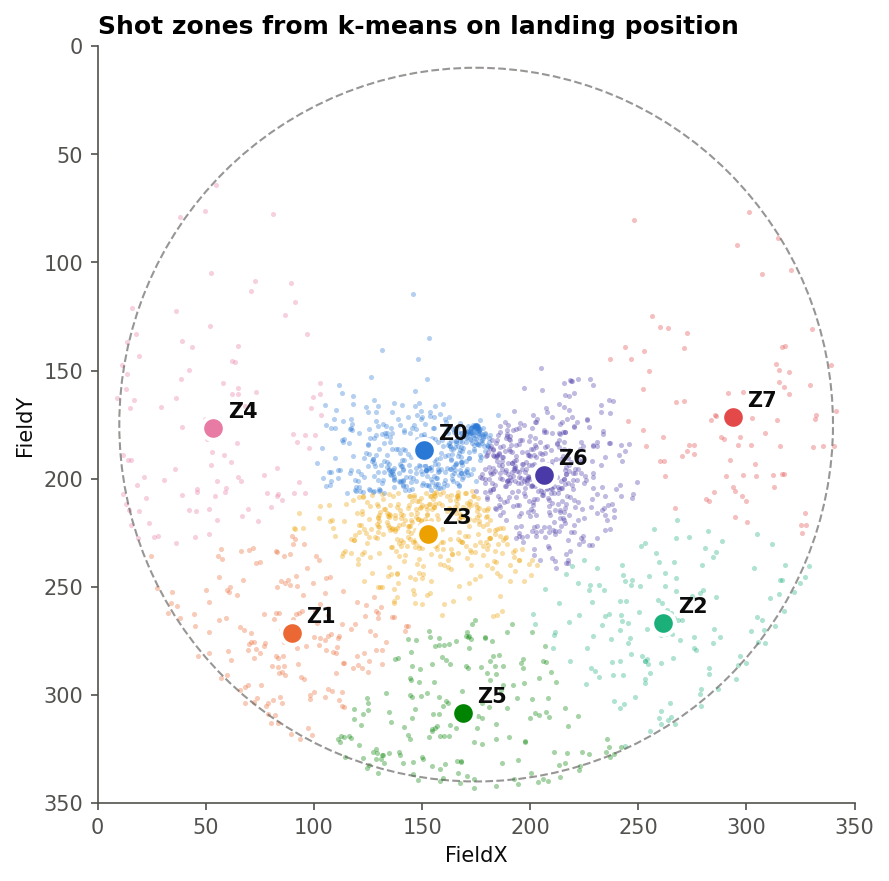

In [7]:
plots.zone_map(clean, zm.centres());

## 5. Predict the zone, holding out one match at a time

In [8]:
params = model.make_params(config.K_ZONES, n_estimators=100)
cv = model.lomo_cv(clean, params=params, verbose=False)
pd.Series(model.summarise(cv.y_true, cv.y_pred, cv.per_match)).round(3)

accuracy                        0.451
weighted_f1                     0.429
macro_f1                        0.368
majority_baseline               0.223
random_baseline                 0.125
improvement_over_baseline       0.228
n_deliveries                 1892.000
mean_match_accuracy             0.451
sd_match_accuracy               0.038
n_matches                      12.000
dtype: float64

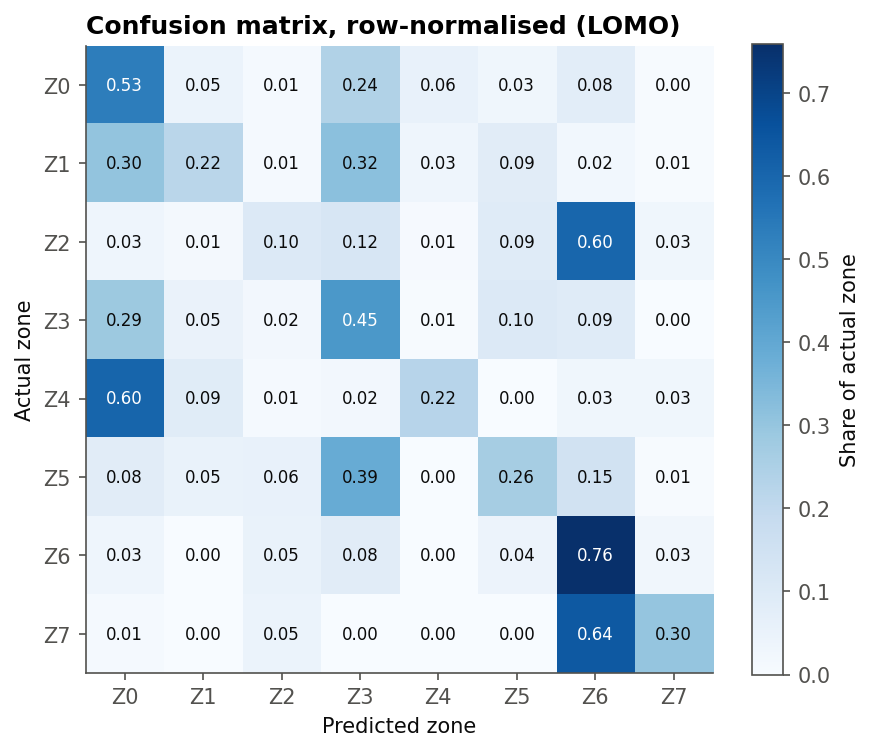

In [9]:
plots.confusion(cv.y_true, cv.y_pred, config.K_ZONES);

## 6. Backtest: is following the recommendation associated with more runs?

A delivery "followed" the recommendation when the batter hit into the predicted zone.

In [10]:
d = cv.deliveries
backtest.followed_summary(d)

,group,n,mean_runs,boundary_pct
0,Followed recommendation,853,0.939,6.448
1,Did not follow,1039,1.488,16.747


In [11]:
backtest.hypothesis_tests(d, n_perm=200)

,test,statistic,p,effect,breslow_day_p
0,"Chi-square (naive, 2 x 6)",84.592,9.168e-17,Cramer's V = 0.2114,NaN
1,Permutation chi-square (within match),84.592,4.975e-03,,NaN
2,"CMH, boundary vs not",46.615,8.640e-12,"OR = 0.343 [0.249, 0.471]",0.278
3,"CMH, scoring shot vs dot",16.097,6.019e-05,"OR = 0.677 [0.559, 0.820]",0.021


In [12]:
backtest.breakdown(d, "phase", order=config.PHASE_ORDER)

,phase,n,runs_followed,runs_not_followed,bnd_pct_followed,bnd_pct_not_followed,odds_ratio,ci_low,ci_high,p,strata
0,Opening (balls 1-49),938,0.602,1.442,0.238,16.023,0.016,0.002,0.104,1.110e-16,12
1,Middle (balls 50-79),595,0.719,1.328,1.799,15.142,0.102,0.040,0.258,5.286e-09,12
2,Death (balls 80-100),359,2.245,1.853,31.613,21.078,1.636,1.008,2.654,4.357e-02,12


## 7. Off-policy evaluation

The naive comparison mixes up decision quality with execution. The doubly-robust estimator values each recommended zone with a reward model fitted on other matches, then corrects it with propensity-weighted residuals.

In [13]:
scored = ope.cross_fitted_rewards(ope.add_propensities(d, cv.proba))
tbl = ope.evaluate_policy(scored, by="phase", order=config.PHASE_ORDER, n_boot=1000)
tbl

,group,n,behaviour,DM,IPS,SNIPS,DR,DR_uplift,uplift_ci_low,uplift_ci_high
0,All deliveries,1892.0,1.240,0.967,0.831,0.959,0.995,-0.245,-0.312,-0.174
1,Opening (balls 1-49),938.0,1.066,0.733,0.506,0.608,0.721,-0.345,-0.451,-0.237
2,Middle (balls 50-79),595.0,1.044,0.777,0.663,0.736,0.816,-0.228,-0.324,-0.112
3,Death (balls 80-100),359.0,2.022,1.895,1.961,2.171,2.012,-0.011,-0.270,0.228


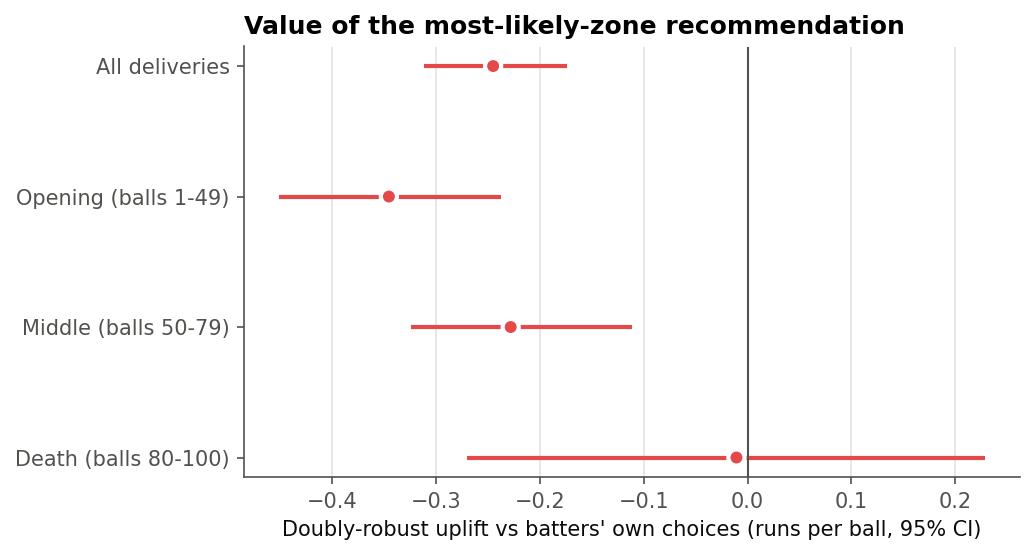

In [14]:
plots.uplift_by_group(tbl, "Value of the most-likely-zone recommendation");